In [10]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [11]:
   assert df.shape == (7043, 21), f"Unexpected shape: {df.shape} — file may be incomplete"

### Data completeness check
The first download was silently cut off (4,747 rows instead of 7,043, with the
last row missing `MonthlyCharges`). This check stops the notebook if the file is
ever incomplete again, instead of letting the analysis run on partial data.

In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### Column types
All 7,043 rows are present and no column has nulls. However, `TotalCharges`
holds money amounts but is stored as text (`str`), so something in it is not a
number. Investigated in the next cell.

In [18]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df[df["TotalCharges"].isna()][["tenure", "MonthlyCharges", "TotalCharges"]]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


### Why was `TotalCharges` text?
11 customers had a blank `TotalCharges`. All of them have `tenure = 0`: they just
signed up and have not been billed yet. The gap is explained, not random, and it
affects only 0.16% of customers, so these rows are dropped before modelling.

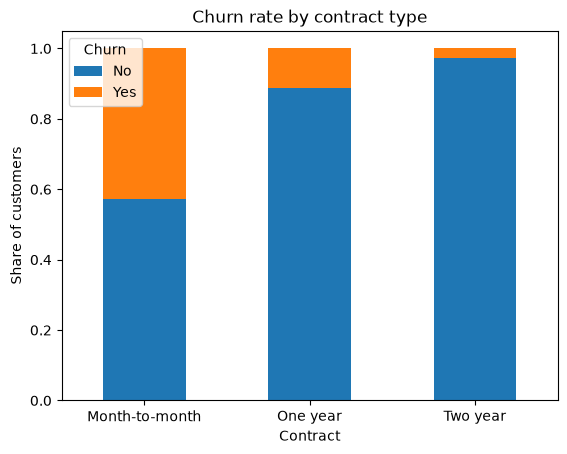

In [19]:
pd.crosstab(df["Contract"], df["Churn"], normalize="index").plot(kind="bar", stacked=True)
plt.title("Churn rate by contract type")
plt.ylabel("Share of customers")
plt.xticks(rotation=0)
plt.show()

### How many customers leave?
- **73.5%** stayed, **26.5%** left.

The classes are **imbalanced**. A model that always predicted "stays" would be
73% accurate while catching zero churners, so accuracy alone is a misleading
metric. We will use recall and ROC-AUC instead.

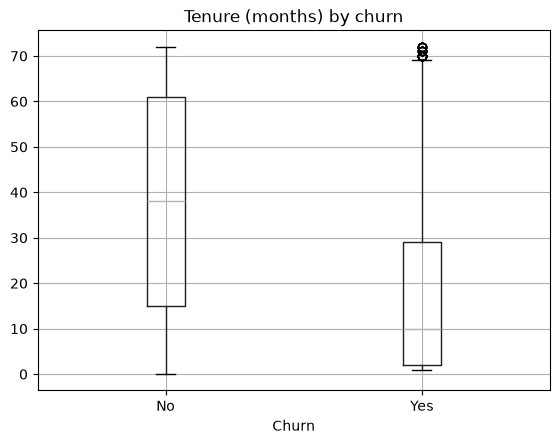

In [20]:
df.boxplot(column="tenure", by="Churn")
plt.title("Tenure (months) by churn")
plt.suptitle("")
plt.show()

### Churn rate by contract type
**How to read it:** each bar is 100% of customers on that contract. The orange
part is the share who left.

| Contract | Churn rate |
|---|---|
| Month-to-month | ~43% |
| One year | ~11% |
| Two year | ~3% |

**Finding:** contract type is the strongest single signal. Month-to-month
customers are about 14 times more likely to leave than two-year customers:
there is no penalty for leaving, so they can go at any time.

**Business implication:** offering month-to-month customers an incentive to move
to a one-year contract could reduce churn directly.

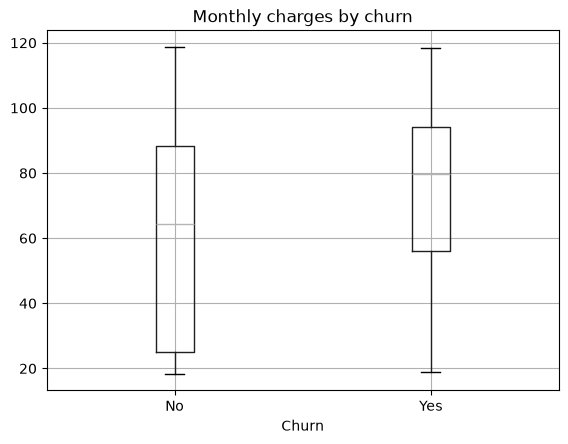

In [21]:
df.boxplot(column="MonthlyCharges", by="Churn")
plt.title("Monthly charges by churn")
plt.suptitle("")
plt.show()

### Monthly charges by churn
| | Median monthly charge | Middle 50% |
|---|---|---|
| Stayed | ~64 | 25–88 |
| Left | ~80 | 56–94 |

**Finding:** customers who leave tend to pay more each month. The boxes overlap
heavily, though, so price is a **weaker** signal than contract type or tenure:
many high payers stay too.

## EDA conclusions
Churn risk is highest for customers who are:
1. on **month-to-month** contracts,
2. **new** (first year),
3. paying **higher monthly bills**.

These are our hypotheses. The model in `02_model.ipynb` tests whether they hold
when all features are considered together.